# Actividad 6 — Decisión de Inversión en Riego
## Caso: Productor de Caña de Azúcar en Pánuco, Veracruz

**Alumno:** Carlos Pulido Rosas  
**Materia:** Tópicos Selectos de Grandes Bases de Datos  
**Maestría en Ciencias de los Datos — UdeG CUCEA · 2026**

---

Este notebook documenta el proceso completo de análisis de decisión bajo incertidumbre para evaluar si un productor de caña de azúcar en Pánuco, Veracruz debe invertir en un sistema de riego. Se construye el árbol de decisión de forma explícita, se calcula la utilidad esperada analíticamente y se valida mediante una simulación de Monte Carlo con 10,000 escenarios.

## 1. Importaciones y parámetros del modelo

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

# Reproducibilidad
RNG = np.random.default_rng(42)

# ── Parámetros generales ─────────────────────────────────────────────────────
HECTARES      = 100          # superficie total (ha)
HORIZON       = 7            # vida útil del sistema (años)
INVESTMENT_HA = 80_000       # inversión por hectárea (MXN) = 4,000 USD × 20
INVESTMENT    = INVESTMENT_HA * HECTARES   # inversión total

# ── Costos anuales (MXN/ha/año) ──────────────────────────────────────────────
COST_TEMPORAL  = 38_000      # costo sin riego
COST_RIEGO_OP  = 55_000      # costo operación con riego
COST_RIEGO_MNT =  8_000      # costo mantenimiento con riego
COST_RIEGO     = COST_RIEGO_OP + COST_RIEGO_MNT   # 63,000

# ── Precios históricos observados (MXN/ton) ──────────────────────────────────
PRICES = [701.49, 757.16, 755.59, 900.95, 829.39, 897.65]
E_PRICE = np.mean(PRICES)

# ── Probabilidad de tormenta severa ─────────────────────────────────────────
P_STORM = 0.05

print(f"Inversión total:        ${INVESTMENT:>12,.0f} MXN")
print(f"Costo anual temporal:   ${COST_TEMPORAL*HECTARES:>12,.0f} MXN/año")
print(f"Costo anual riego:      ${COST_RIEGO*HECTARES:>12,.0f} MXN/año")
print(f"Precio promedio E[P]:   ${E_PRICE:>12,.2f} MXN/ton")

Inversión total:        $   8,000,000 MXN
Costo anual temporal:   $   3,800,000 MXN/año
Costo anual riego:      $   6,300,000 MXN/año
Precio promedio E[P]:   $      807.04 MXN/ton


## 2. Condiciones hídricas y rendimientos

Hay cuatro categorías de condición hídrica anual con sus respectivas probabilidades y rendimientos para cada alternativa.

In [2]:
# ── Condiciones hídricas ─────────────────────────────────────────────────────
condiciones = {
    "Normal / anormal seca": {"prob": 0.40},
    "Sequía moderada":       {"prob": 0.30},
    "Sequía severa":         {"prob": 0.20},
    "Sequía extrema":        {"prob": 0.10},
}

# Verificar que las probabilidades sumen 1
assert abs(sum(v["prob"] for v in condiciones.values()) - 1.0) < 1e-9

# ── Rendimientos temporales (ton/ha/año) ─────────────────────────────────────
rendimiento_temporal = {
    "Normal / anormal seca": 60,
    "Sequía moderada":       50,
    "Sequía severa":         40,
    "Sequía extrema":        25,
}

# ── Rendimientos con riego (ton/ha/año) ──────────────────────────────────────
# En condición normal: distribución estocástica
riego_normal_dist = [
    {"prob": 0.50, "yield": 90},
    {"prob": 0.30, "yield": 120},
    {"prob": 0.20, "yield": 200},
]
# En otras condiciones: determinístico
rendimiento_riego = {
    "Sequía moderada": 90,
    "Sequía severa":   70,
    "Sequía extrema":  40,
}

# ── Resumen en tabla ─────────────────────────────────────────────────────────
df_rend = pd.DataFrame([
    {
        "Condición hídrica": cond,
        "Probabilidad": f"{info['prob']*100:.0f}%",
        "Temporal (ton/ha)": rendimiento_temporal[cond],
        "Riego (ton/ha)": "50%→90 / 30%→120 / 20%→200" if cond == "Normal / anormal seca"
                          else rendimiento_riego[cond]
    }
    for cond, info in condiciones.items()
])

print("Rendimientos por condición hídrica (tormenta severa → 0 ton/ha en ambas alternativas)\n")
print(df_rend.to_string(index=False))

Rendimientos por condición hídrica (tormenta severa → 0 ton/ha en ambas alternativas)

    Condición hídrica Probabilidad  Temporal (ton/ha)             Riego (ton/ha)
Normal / anormal seca          40%                 60 50%→90 / 30%→120 / 20%→200
      Sequía moderada          30%                 50                         90
        Sequía severa          20%                 40                         70
       Sequía extrema          10%                 25                         40


## 3. Árbol de decisión — enumeración explícita de escenarios

Cada hoja del árbol representa un escenario con su probabilidad combinada y la utilidad anual para cada alternativa.

**Estructura del árbol:**
```
Decisión
├── Sin riego (temporal)
│   ├── Tormenta (5%)              → yield = 0
│   └── Sin tormenta (95%)
│       ├── Normal (40%)           → yield = 60 ton/ha
│       ├── Seq. moderada (30%)    → yield = 50 ton/ha
│       ├── Seq. severa (20%)      → yield = 40 ton/ha
│       └── Seq. extrema (10%)     → yield = 25 ton/ha
└── Con riego
    ├── Tormenta (5%)              → yield = 0
    └── Sin tormenta (95%)
        ├── Normal (40%)
        │   ├── 90 ton/ha (50%)
        │   ├── 120 ton/ha (30%)
        │   └── 200 ton/ha (20%)
        ├── Seq. moderada (30%)    → yield = 90 ton/ha
        ├── Seq. severa (20%)      → yield = 70 ton/ha
        └── Seq. extrema (10%)     → yield = 40 ton/ha
```

In [3]:
def utilidad_anual(rendimiento_ton_ha, costo_por_ha, precio=E_PRICE):
    """
    Utilidad anual para 100 ha.
    Utilidad = (Rendimiento × Precio − Costo/ha) × 100 ha
    """
    return (rendimiento_ton_ha * precio - costo_por_ha) * HECTARES


# Construir todos los escenarios hoja del árbol
escenarios = []

# ── Tormenta severa (afecta ambas alternativas igual) ────────────────────────
escenarios.append({
    "escenario":      "Tormenta severa",
    "sub_cond":       "—",
    "prob":           P_STORM,
    "yield_temporal": 0,
    "yield_riego":    0,
    "util_temporal":  utilidad_anual(0, COST_TEMPORAL),
    "util_riego":     utilidad_anual(0, COST_RIEGO),
})

p_no_tormenta = 1 - P_STORM

# ── Sin tormenta: ramificar por condición hídrica ────────────────────────────
for cond, info in condiciones.items():
    p_cond = info["prob"] * p_no_tormenta
    yt = rendimiento_temporal[cond]

    if cond == "Normal / anormal seca":
        # Sub-distribución estocástica para riego en condición normal
        for sub in riego_normal_dist:
            yr = sub["yield"]
            escenarios.append({
                "escenario":      cond,
                "sub_cond":       f"Riego: {yr} ton/ha ({sub['prob']*100:.0f}%)",
                "prob":           p_cond * sub["prob"],
                "yield_temporal": yt,
                "yield_riego":    yr,
                "util_temporal":  utilidad_anual(yt, COST_TEMPORAL),
                "util_riego":     utilidad_anual(yr, COST_RIEGO),
            })
    else:
        yr = rendimiento_riego[cond]
        escenarios.append({
            "escenario":      cond,
            "sub_cond":       "—",
            "prob":           p_cond,
            "yield_temporal": yt,
            "yield_riego":    yr,
            "util_temporal":  utilidad_anual(yt, COST_TEMPORAL),
            "util_riego":     utilidad_anual(yr, COST_RIEGO),
        })

df_esc = pd.DataFrame(escenarios)

# Verificar que las probabilidades sumen 1
assert abs(df_esc["prob"].sum() - 1.0) < 1e-9, "Las probabilidades no suman 1"
print(f"Suma de probabilidades: {df_esc['prob'].sum():.4f} ✓\n")

# Mostrar tabla
display_df = df_esc[["escenario", "sub_cond", "prob", "yield_temporal", "util_temporal", "yield_riego", "util_riego"]].copy()
display_df["prob"]          = display_df["prob"].apply(lambda x: f"{x*100:.1f}%")
display_df["util_temporal"] = display_df["util_temporal"].apply(lambda x: f"${x:,.0f}")
display_df["util_riego"]    = display_df["util_riego"].apply(lambda x: f"${x:,.0f}")
display_df.columns = ["Condición", "Sub-condición", "P(escenario)",
                      "Rend. Temporal", "Util. Temporal", "Rend. Riego", "Util. Riego"]
print(display_df.to_string(index=False))

Suma de probabilidades: 1.0000 ✓

            Condición           Sub-condición P(escenario)  Rend. Temporal Util. Temporal  Rend. Riego Util. Riego
      Tormenta severa                       —         5.0%               0    $-3,800,000            0 $-6,300,000
Normal / anormal seca  Riego: 90 ton/ha (50%)        19.0%              60     $1,042,230           90    $963,345
Normal / anormal seca Riego: 120 ton/ha (30%)        11.4%              60     $1,042,230          120  $3,384,460
Normal / anormal seca Riego: 200 ton/ha (20%)         7.6%              60     $1,042,230          200  $9,840,767
      Sequía moderada                       —        28.5%              50       $235,192           90    $963,345
        Sequía severa                       —        19.0%              40      $-571,847           70   $-650,732
       Sequía extrema                       —         9.5%              25    $-1,782,404           40 $-3,071,847


## 4. Utilidad esperada anual

La utilidad esperada anual es la suma ponderada de las utilidades de cada escenario por su probabilidad de ocurrencia:

$$E[U] = \sum_{i} P(\text{escenario}_i) \times U(\text{escenario}_i)$$

In [4]:
# ── Utilidad esperada anual (analítica) ───────────────────────────────────────
E_util_temporal = sum(s["prob"] * s["util_temporal"] for s in escenarios)
E_util_riego    = sum(s["prob"] * s["util_riego"]    for s in escenarios)

# ── Rendimiento esperado ─────────────────────────────────────────────────────
E_yield_temporal = sum(s["prob"] * s["yield_temporal"] for s in escenarios)
E_yield_riego    = sum(s["prob"] * s["yield_riego"]    for s in escenarios)

print("─" * 55)
print(f"{'Concepto':<35} {'Temporal':>9} {'Riego':>9}")
print("─" * 55)
print(f"{'Rendimiento esperado (ton/ha/año)':<35} {E_yield_temporal:>9.3f} {E_yield_riego:>9.3f}")
print(f"{'Precio esperado (MXN/ton)':<35} {E_PRICE:>9,.2f} {E_PRICE:>9,.2f}")
print(f"{'Ingreso bruto esperado (MXN/año)':<35} {E_yield_temporal*E_PRICE*HECTARES:>9,.0f} {E_yield_riego*E_PRICE*HECTARES:>9,.0f}")
print(f"{'Costo total anual (MXN/año)':<35} {-COST_TEMPORAL*HECTARES:>9,.0f} {-COST_RIEGO*HECTARES:>9,.0f}")
print("─" * 55)
print(f"{'Utilidad esperada anual (MXN/año)':<35} {E_util_temporal:>9,.0f} {E_util_riego:>9,.0f}")
print("─" * 55)

───────────────────────────────────────────────────────
Concepto                             Temporal     Riego
───────────────────────────────────────────────────────
Rendimiento esperado (ton/ha/año)      47.025    88.730
Precio esperado (MXN/ton)              807.04    807.04
Ingreso bruto esperado (MXN/año)    3,795,098 7,160,851
Costo total anual (MXN/año)         -3,800,000 -6,300,000
───────────────────────────────────────────────────────
Utilidad esperada anual (MXN/año)      -4,902   860,851
───────────────────────────────────────────────────────


## 5. Utilidad acumulada esperada — horizonte de 7 años

Asumiendo independencia entre años, la utilidad acumulada esperada es:

$$U_{\text{temporal}}^{(7)} = E[U_{\text{temporal}}] \times 7$$

$$U_{\text{riego}}^{(7)} = E[U_{\text{riego}}] \times 7 - \text{Inversión inicial}$$

In [5]:
# ── Utilidad acumulada 7 años ─────────────────────────────────────────────────
cum_temporal_7 = E_util_temporal * HORIZON
cum_riego_7    = E_util_riego    * HORIZON - INVESTMENT

print("─" * 60)
print(f"{'Concepto':<40} {'Temporal':>9} {'Riego':>9}")
print("─" * 60)
print(f"{'Utilidad esperada anual (MXN)':<40} {E_util_temporal:>9,.0f} {E_util_riego:>9,.0f}")
print(f"{'Utilidad operativa acumulada (×7)':<40} {E_util_temporal*7:>9,.0f} {E_util_riego*7:>9,.0f}")
print(f"{'Inversión inicial (MXN)':<40} {'$0':>9} {-INVESTMENT:>9,.0f}")
print("─" * 60)
print(f"{'Utilidad NETA acumulada 7 años (MXN)':<40} {cum_temporal_7:>9,.0f} {cum_riego_7:>9,.0f}")
print("─" * 60)

# ── ¿Cuántos años tarda en recuperarse la inversión? ─────────────────────────
diferencia_anual = E_util_riego - E_util_temporal
payback = INVESTMENT / diferencia_anual if diferencia_anual > 0 else float('inf')
print(f"\nVentaja operativa del riego vs temporal: ${diferencia_anual:,.0f} MXN/año")
print(f"Años necesarios para recuperar la inversión: {payback:.1f} años")
print(f"(La vida útil del sistema es de {HORIZON} años)")

────────────────────────────────────────────────────────────
Concepto                                  Temporal     Riego
────────────────────────────────────────────────────────────
Utilidad esperada anual (MXN)               -4,902   860,851
Utilidad operativa acumulada (×7)          -34,316 6,025,958
Inversión inicial (MXN)                         $0 -8,000,000
────────────────────────────────────────────────────────────
Utilidad NETA acumulada 7 años (MXN)       -34,316 -1,974,042
────────────────────────────────────────────────────────────

Ventaja operativa del riego vs temporal: $865,753 MXN/año
Años necesarios para recuperar la inversión: 9.2 años
(La vida útil del sistema es de 7 años)


## 6. Visualización: comparación de utilidad acumulada por año

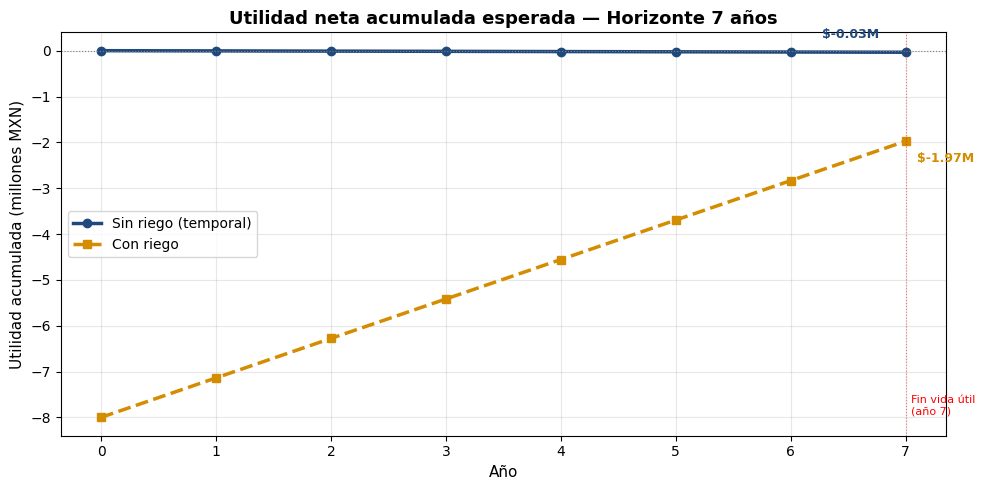

Figura guardada.


In [6]:
años = np.arange(0, HORIZON + 1)

# Acumulado por año
util_t_acum = np.array([E_util_temporal * t for t in años])
util_r_acum = np.array([-INVESTMENT + E_util_riego * t for t in años])

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(años, util_t_acum / 1e6, 'o-', color='#1F497D', linewidth=2.5,
        markersize=6, label='Sin riego (temporal)')
ax.plot(años, util_r_acum / 1e6, 's--', color='#D48C00', linewidth=2.5,
        markersize=6, label='Con riego')

ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax.axvline(HORIZON, color='red', linewidth=0.8, linestyle=':', alpha=0.5)
ax.text(HORIZON + 0.05, ax.get_ylim()[0] * 0.95, 'Fin vida útil\n(año 7)',
        color='red', fontsize=8, va='bottom')

ax.set_xlabel('Año', fontsize=11)
ax.set_ylabel('Utilidad acumulada (millones MXN)', fontsize=11)
ax.set_title('Utilidad neta acumulada esperada — Horizonte 7 años', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.set_xticks(años)
ax.grid(True, alpha=0.3)

# Anotar valores finales
ax.annotate(f'${cum_temporal_7/1e6:.2f}M', xy=(7, util_t_acum[-1]/1e6),
            xytext=(-60, 10), textcoords='offset points',
            color='#1F497D', fontweight='bold', fontsize=9)
ax.annotate(f'${cum_riego_7/1e6:.2f}M', xy=(7, util_r_acum[-1]/1e6),
            xytext=(8, -15), textcoords='offset points',
            color='#D48C00', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('../tareas/actividades/actividad-6/fig_utilidad_acumulada.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura guardada.")

## 7. Simulación de Monte Carlo — 10,000 escenarios

El análisis analítico usa el precio esperado puntual. La simulación incorpora la variabilidad real del precio sorteando de la distribución discreta de precios históricos, lo que captura mejor la incertidumbre total del sistema.

In [7]:
N_SIM = 10_000

# Arreglos de parámetros para operaciones vectorizadas
prices         = np.array(PRICES)
drought_probs  = np.array([0.40, 0.30, 0.20, 0.10])
yields_t       = np.array([60.0, 50.0, 40.0, 25.0])   # temporal por condición
yields_r_det   = np.array([121.0, 90.0, 70.0, 40.0])  # riego determinístico
# (121 = E[yield_riego_normal] = 0.5×90 + 0.3×120 + 0.2×200)

cum_temporal = np.zeros(N_SIM)
cum_riego    = np.zeros(N_SIM)

print(f"Simulando {N_SIM:,} escenarios × {HORIZON} años...")

for año in range(HORIZON):
    # Sortear precio (uniforme discreta)
    precio = prices[RNG.integers(0, len(prices), N_SIM)]

    # Sortear condición hídrica (0=normal, 1=mod, 2=severa, 3=extrema)
    d_idx = RNG.choice(4, N_SIM, p=drought_probs)

    # Sortear tormenta severa
    tormenta = RNG.random(N_SIM) < P_STORM

    # Rendimiento temporal
    yt = np.where(tormenta, 0.0, yields_t[d_idx])

    # Rendimiento riego
    yr_base = np.where(tormenta, 0.0, yields_r_det[d_idx])
    # En condición normal sin tormenta: sortear sub-distribución
    sub = RNG.random(N_SIM)
    yr_normal = np.where(sub < 0.50, 90.0,
                np.where(sub < 0.80, 120.0, 200.0))
    es_normal = (~tormenta) & (d_idx == 0)
    yr = np.where(es_normal, yr_normal, yr_base)

    # Utilidades anuales
    cum_temporal += (yt * precio - COST_TEMPORAL) * HECTARES
    cum_riego    += (yr * precio - COST_RIEGO)    * HECTARES

# Descontar inversión inicial de la alternativa con riego
cum_riego -= INVESTMENT

print("Simulación completa.")

Simulando 10,000 escenarios × 7 años...
Simulación completa.


## 8. Resultados de la simulación

In [8]:
# ── Estadísticas descriptivas ────────────────────────────────────────────────
def stats(arr, label):
    return {
        "Alternativa":      label,
        "Media":            np.mean(arr),
        "Mediana":          np.median(arr),
        "Desv. estándar":   np.std(arr),
        "Percentil 5%":     np.percentile(arr,  5),
        "Percentil 95%":    np.percentile(arr, 95),
        "Mínimo":           np.min(arr),
        "Máximo":           np.max(arr),
    }

df_stats = pd.DataFrame([stats(cum_temporal, "Sin riego (temporal)"),
                          stats(cum_riego,    "Con riego")])
df_stats = df_stats.set_index("Alternativa")

# Formatear como MXN
for col in df_stats.columns:
    df_stats[col] = df_stats[col].apply(lambda x: f"${x:>14,.0f}")

print("Estadísticas de la simulación — Utilidad acumulada 7 años (MXN)\n")
print(df_stats.T.to_string())

# ── Criterio de mayoría de escenarios ────────────────────────────────────────
p_riego_gana = np.mean(cum_riego > cum_temporal)
print(f"\n{'─'*50}")
print(f"P(riego > temporal): {p_riego_gana*100:.1f}%  →  {(1-p_riego_gana)*100:.1f}% a favor del temporal")
print(f"{'─'*50}")

Estadísticas de la simulación — Utilidad acumulada 7 años (MXN)

Alternativa    Sin riego (temporal)        Con riego
Media               $       -59,979  $    -2,087,268
Mediana             $       292,405  $    -2,652,090
Desv. estándar      $     3,415,982  $     9,036,704
Percentil 5%        $    -6,103,296  $   -16,086,886
Percentil 95%       $     4,987,906  $    13,476,621
Mínimo              $   -14,638,885  $   -32,373,320
Máximo              $     9,443,930  $    45,471,640

──────────────────────────────────────────────────
P(riego > temporal): 35.3%  →  64.7% a favor del temporal
──────────────────────────────────────────────────


## 9. Visualización: distribución de resultados simulados

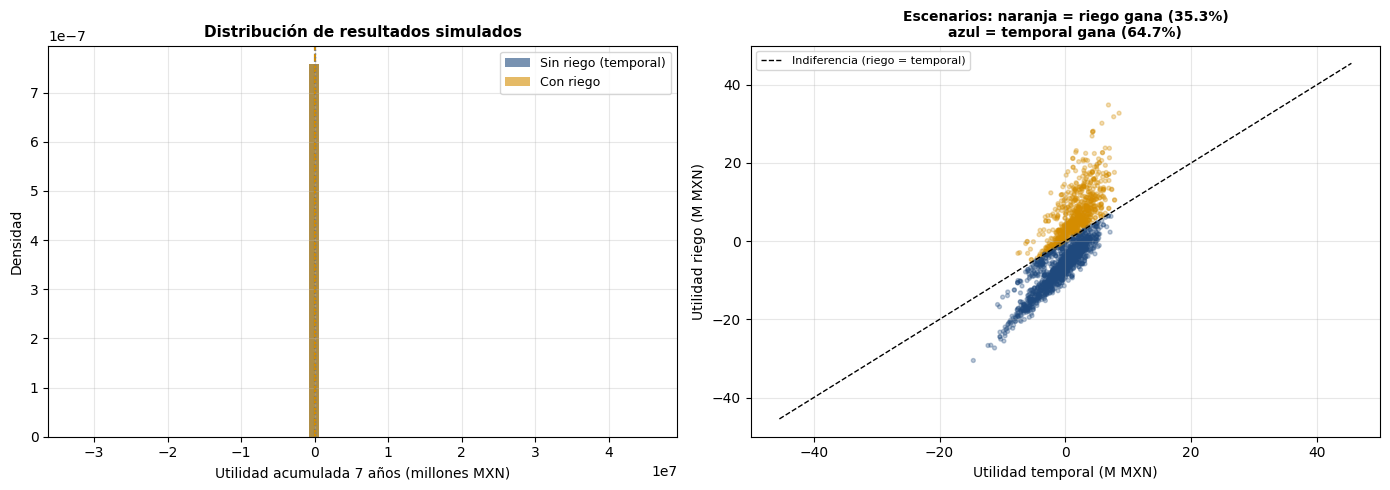

Figura guardada.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Histogramas solapados ────────────────────────────────────────────────────
ax = axes[0]
bins = np.linspace(
    min(cum_temporal.min(), cum_riego.min()),
    max(cum_temporal.max(), cum_riego.max()),
    60
)
ax.hist(cum_temporal / 1e6, bins=bins, alpha=0.6, color='#1F497D',
        label='Sin riego (temporal)', density=True)
ax.hist(cum_riego    / 1e6, bins=bins, alpha=0.6, color='#D48C00',
        label='Con riego', density=True)
ax.axvline(np.mean(cum_temporal) / 1e6, color='#1F497D', linestyle='--', linewidth=1.5)
ax.axvline(np.mean(cum_riego)    / 1e6, color='#D48C00', linestyle='--', linewidth=1.5)
ax.axvline(0, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('Utilidad acumulada 7 años (millones MXN)', fontsize=10)
ax.set_ylabel('Densidad', fontsize=10)
ax.set_title('Distribución de resultados simulados', fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── Scatter: temporal vs riego por escenario (muestra 2000) ──────────────────
ax2 = axes[1]
idx = RNG.integers(0, N_SIM, 2000)
colores = np.where(cum_riego[idx] > cum_temporal[idx], '#D48C00', '#1F497D')
ax2.scatter(cum_temporal[idx] / 1e6, cum_riego[idx] / 1e6,
            c=colores, alpha=0.3, s=8)
lim = max(abs(cum_temporal).max(), abs(cum_riego).max()) / 1e6
ax2.plot([-lim, lim], [-lim, lim], 'k--', linewidth=1, label='Indiferencia (riego = temporal)')
ax2.set_xlabel('Utilidad temporal (M MXN)', fontsize=10)
ax2.set_ylabel('Utilidad riego (M MXN)', fontsize=10)
ax2.set_title(f'Escenarios: naranja = riego gana ({p_riego_gana*100:.1f}%)\n'
              f'azul = temporal gana ({(1-p_riego_gana)*100:.1f}%)', fontsize=10, fontweight='bold')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../tareas/actividades/actividad-6/fig_simulacion.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura guardada.")

## 10. Comparación de criterios de decisión

In [10]:
mean_t = np.mean(cum_temporal)
mean_r = np.mean(cum_riego)

criterios = [
    {
        "Criterio": "Mayor utilidad esperada (analítica)",
        "Temporal": f"${cum_temporal_7:,.0f}",
        "Riego":    f"${cum_riego_7:,.0f}",
        "Decisión": "✓ Temporal" if cum_temporal_7 > cum_riego_7 else "✓ Riego",
    },
    {
        "Criterio": "Mayoría de escenarios favorables (simulación)",
        "Temporal": f"{(1-p_riego_gana)*100:.1f}%",
        "Riego":    f"{p_riego_gana*100:.1f}%",
        "Decisión": "✓ Temporal" if p_riego_gana < 0.50 else "✓ Riego",
    },
    {
        "Criterio": "Utilidad media simulada (7 años)",
        "Temporal": f"${mean_t:,.0f}",
        "Riego":    f"${mean_r:,.0f}",
        "Decisión": "✓ Temporal" if mean_t > mean_r else "✓ Riego",
    },
]

df_crit = pd.DataFrame(criterios).set_index("Criterio")
print("Comparación de criterios de decisión\n")
print(df_crit.to_string())

Comparación de criterios de decisión

                                               Temporal        Riego    Decisión
Criterio                                                                        
Mayor utilidad esperada (analítica)            $-34,316  $-1,974,042  ✓ Temporal
Mayoría de escenarios favorables (simulación)     64.7%        35.3%  ✓ Temporal
Utilidad media simulada (7 años)               $-59,979  $-2,087,268  ✓ Temporal


## 11. Análisis de sensibilidad — ¿a qué precio conviene invertir?

La inversión en riego tiene una ventaja operativa de ~$865,000 MXN/año. La pregunta es: ¿a qué precio de la caña se recupera la inversión de $8M en 7 años?

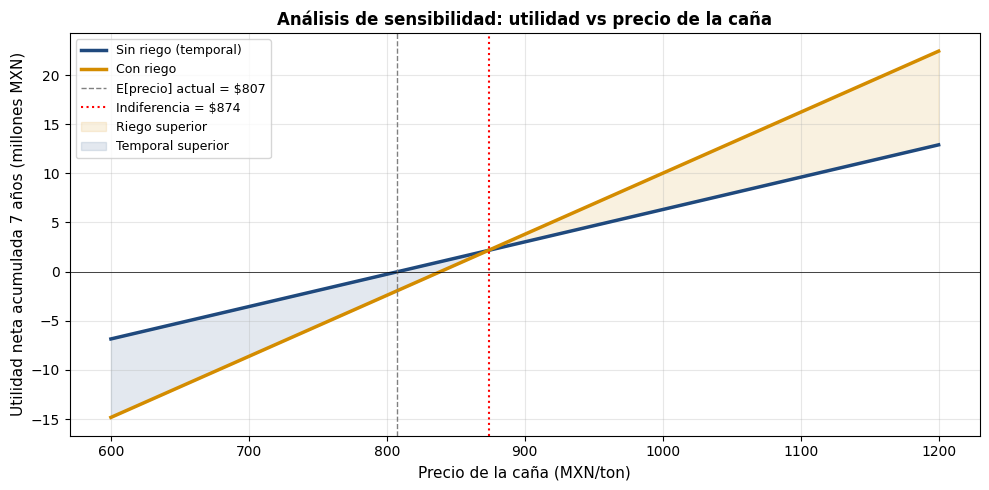

Precio de indiferencia: $874 MXN/ton
Precio esperado actual:  $807 MXN/ton
El riego conviene si el precio promedio supera $874 MXN/ton


In [11]:
precios_eval = np.linspace(600, 1200, 200)
util_t_7    = []
util_r_7    = []

for p in precios_eval:
    # Utilidad anual a ese precio
    ut = sum(s["prob"] * (s["yield_temporal"] * p - COST_TEMPORAL) * HECTARES
             for s in escenarios)
    ur = sum(s["prob"] * (s["yield_riego"]    * p - COST_RIEGO)    * HECTARES
             for s in escenarios)
    util_t_7.append(ut * HORIZON)
    util_r_7.append(ur * HORIZON - INVESTMENT)

util_t_7 = np.array(util_t_7)
util_r_7 = np.array(util_r_7)

# Precio de indiferencia
idx_cross = np.argmin(np.abs(util_r_7 - util_t_7))
precio_indiferencia = precios_eval[idx_cross]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(precios_eval, util_t_7 / 1e6, color='#1F497D', linewidth=2.5, label='Sin riego (temporal)')
ax.plot(precios_eval, util_r_7 / 1e6, color='#D48C00', linewidth=2.5, label='Con riego')
ax.axvline(E_PRICE,               color='gray',  linestyle='--', linewidth=1, label=f'E[precio] actual = ${E_PRICE:.0f}')
ax.axvline(precio_indiferencia,   color='red',   linestyle=':',  linewidth=1.5, label=f'Indiferencia = ${precio_indiferencia:.0f}')
ax.axhline(0, color='black', linewidth=0.5)
ax.fill_between(precios_eval, util_t_7/1e6, util_r_7/1e6,
                where=(util_r_7 > util_t_7), alpha=0.12, color='#D48C00', label='Riego superior')
ax.fill_between(precios_eval, util_t_7/1e6, util_r_7/1e6,
                where=(util_r_7 <= util_t_7), alpha=0.12, color='#1F497D', label='Temporal superior')
ax.set_xlabel('Precio de la caña (MXN/ton)', fontsize=11)
ax.set_ylabel('Utilidad neta acumulada 7 años (millones MXN)', fontsize=11)
ax.set_title('Análisis de sensibilidad: utilidad vs precio de la caña', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../tareas/actividades/actividad-6/fig_sensibilidad.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Precio de indiferencia: ${precio_indiferencia:.0f} MXN/ton")
print(f"Precio esperado actual:  ${E_PRICE:.0f} MXN/ton")
print(f"El riego conviene si el precio promedio supera ${precio_indiferencia:.0f} MXN/ton")

## 12. Conclusión

In [12]:
decision = "NO INVERTIR en riego" if cum_temporal_7 > cum_riego_7 else "INVERTIR en riego"

print("═" * 60)
print(f"  RECOMENDACIÓN: {decision}")
print("═" * 60)
print()
print(f"  Utilidad esperada analítica (7 años):")
print(f"    Temporal: ${cum_temporal_7:>14,.0f} MXN")
print(f"    Riego:    ${cum_riego_7:>14,.0f} MXN")
print()
print(f"  Simulación Monte Carlo ({N_SIM:,} escenarios):")
print(f"    Riego gana en el {p_riego_gana*100:.1f}% de los escenarios")
print(f"    Temporal gana en el {(1-p_riego_gana)*100:.1f}% de los escenarios")
print()
print(f"  Precio de indiferencia: ${precio_indiferencia:.0f} MXN/ton")
print(f"  Precio esperado actual:  ${E_PRICE:.0f} MXN/ton")
print()
print(f"  La inversión de $8,000,000 MXN tarda {INVESTMENT/(E_util_riego-E_util_temporal):.1f} años")
print(f"  en recuperarse (vida útil del sistema: {HORIZON} años)")
print("═" * 60)

════════════════════════════════════════════════════════════
  RECOMENDACIÓN: NO INVERTIR en riego
════════════════════════════════════════════════════════════

  Utilidad esperada analítica (7 años):
    Temporal: $       -34,316 MXN
    Riego:    $    -1,974,042 MXN

  Simulación Monte Carlo (10,000 escenarios):
    Riego gana en el 35.3% de los escenarios
    Temporal gana en el 64.7% de los escenarios

  Precio de indiferencia: $874 MXN/ton
  Precio esperado actual:  $807 MXN/ton

  La inversión de $8,000,000 MXN tarda 9.2 años
  en recuperarse (vida útil del sistema: 7 años)
════════════════════════════════════════════════════════════
